# TweetEval – Offensive Language Detection
## Notebook 03 · Stop-words, lemmatisation, vectorisation


### Order of this notebook (follows the assignment)
**Part 2 – Text preprocessing (continued from notebook 02)**
1. Remove stop-words (*mots vides*: "the", "is", "and"…) – with negations protected
2. Optional: lemmatisation (reduction of words to their base form)
3. Create the final `text_clean` column
4. Justify the cleaning choices (negations, stop-words, hashtags, capitals…)

**Part 3 – Vectorisation**
5. TF-IDF vectoriser · 6. or Bag of Words · 7. or word embeddings (Word2Vec / BERT, optional)

### Principle: a fair comparison
We do not assume that "more preprocessing = better": every choice is **measured**. Only **one thing changes** between two
compared variants; everything else is identical: same splits, same settings (`src/config.py`), same model (Logistic Regression), same random seed.
Variants are compared on the **validation set** and re-checked by **5-fold cross-validation on train**; the **test set is never used** to choose anything.

| Variant | Transformation applied to the notebook-02 text |
|---|---|
| **A_clean_only** | none (reference / baseline) |
| **B_stopwords** | + stop-word removal, negations protected (`not`, `no`, `never` are kept, because "not good" ≠ "good") |
| **B2_stopwords_keep_pronouns** | + stop-word removal, but `you`, `he`, `she`… are kept ("you are an idiot" needs the "you") |
| **B3_stopwords_drop_user** | + stop-word removal and the placeholder `user` (replacement of @mentions) removed too |
| **C_stopwords_lemma** | + stop-word removal + lemmatisation |

### Contents
1. [Setup](#1) · 2. [Loading](#2) · 3. [Running the variants](#3) · 4. [Stop-word removal](#4) · 5. [Lemmatisation](#5) ·
6. [Robustness (cross-validation)](#6) · 7. [Creating the final `text_clean`](#7) · 8. [Justification of the cleaning choices](#8) ·
9. [Vectorisation: TF-IDF vs Bag of Words](#9) · 10. [Optional: word embeddings](#10) · 11. [Saving](#11)

> **How to read this notebook.** Code cells are commented line by line; every result cell is followed by a **Results explained** or **Reading** cell.

<a id="1"></a>
## 1. Setup
Imports and project modules. Reusable logic lives in `src/` so that the **same** preprocessing is used in every notebook and in the final pipeline.

In [2]:
import sys, warnings, time               # sys: import path | warnings: hide noise | time: (optional) timing
from collections import Counter          # word counting
from pathlib import Path                 # OS-independent paths

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 120)

# Project root (works from the root folder or from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # lets Python find the `src` package

from src import config                                   # central settings: random seed, TF-IDF parameters...
from src.utils import setup_paths, savefig               # standard folders + figure saving
P = setup_paths("03_preprocessing_experiments")          # outputs go to results/*/03_preprocessing_experiments/

# Make sure every output folder exists (parents=True creates missing parents; exist_ok=True never fails)
for d in (P.figures, P.metrics, P.processed):
    Path(d).mkdir(parents=True, exist_ok=True)

from sklearn.linear_model import LogisticRegression                       # the single classifier used everywhere
from sklearn.pipeline import Pipeline                                      # "vectoriser -> classifier" in one object
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer   # TF-IDF and Bag of Words
from sklearn.model_selection import StratifiedKFold, cross_val_score      # robust evaluation

from src.features import fit_tfidf, transform_tfidf      # fit on train / transform other sets (no leakage)
from src.evaluation import compute_metrics, get_confusion_matrix   # accuracy, precision, recall, F1 + confusion matrix
from src.visualization import plot_confusion_matrices    # grid of confusion-matrix heatmaps
from src.final_pipeline import VARIANTS, make_preprocessor
# VARIANTS: dict {variant name -> settings}; make_preprocessor(**settings) returns a function text -> transformed text

print("Project root:", P.root)
print("Figures ->", P.figures)
print("Metrics ->", P.metrics)

Project root: C:\Users\ASUS\Desktop\TweetEval-offensiveML
Figures -> C:\Users\ASUS\Desktop\TweetEval-offensiveML\results\figures\03_preprocessing_experiments
Metrics -> C:\Users\ASUS\Desktop\TweetEval-offensiveML\results\metrics\03_preprocessing_experiments


**Reading.** The printed paths confirm where the notebook will write its outputs (the folders are created if missing).
If they point to an unexpected place, the notebook was launched from the wrong directory.

<a id="2"></a>
## 2. Loading the cleaned data
We load the files produced by notebook 02 (columns `text`, `text_clean`, `label`).
`keep_default_na=False` keeps empty cleaned tweets as empty strings (otherwise pandas turns them into `NaN` and the text functions crash).
The test set is loaded only to produce its final version in section 11; **it is not used for any decision**.

In [3]:
train = pd.read_csv(P.processed / "train_clean.csv", keep_default_na=False)
val   = pd.read_csv(P.processed / "val_clean.csv",   keep_default_na=False)
test  = pd.read_csv(P.processed / "test_clean.csv",  keep_default_na=False)
print(f"train: {len(train)} tweets | val: {len(val)} tweets | test: {len(test)} tweets")
print("TF-IDF settings:", config.TFIDF_PARAMS)       # the same settings are reused for every variant
display(train[["text", "text_clean", "label"]].head(5))

train: 11916 tweets | val: 1324 tweets | test: 860 tweets
TF-IDF settings: {'max_features': 20000, 'ngram_range': (1, 2), 'min_df': 2, 'token_pattern': "[a-z0-9'*]+"}


,text,text_clean,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become...,user bono who cares soon people will understand that they gain nothing from following a phony celebrity become a lea...,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight years the republicans denied obama's picks breitbarters outrage is as phony as their fake president,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with ...,user get him some line help he is gonna be just fine as the game went on you could see him progressing more with his...,0
3,@user @user She is great. Hi Fiona!,user user she is great hi fiona,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could...,user she has become a parody unto herself she has certainly taken some heat for being such an well idiot could be op...,1


**Reading.** We check the sizes of the splits, the TF-IDF parameters that stay fixed during the experiments, and that `text_clean`
(the notebook-02 output) looks like a cleaned version of `text`. This notebook-02 column is called the **base text** below.

<a id="3"></a>
## 3. Running the variants
For each variant we follow the same recipe:

1. transform the base text with the variant's preprocessing function;
2. **fit** TF-IDF on the **training** texts only (vocabulary and word weights);
3. only **transform** the validation texts with the fitted vectoriser (otherwise validation information leaks into training: *data leakage*);
4. train a Logistic Regression;
5. predict the validation set and store the metrics.

The next sections (stop-words, lemmatisation) simply read different rows of the resulting table.

In [4]:
records = []   # one dict of results per variant
cms = {}       # confusion matrix per variant
texts = {}     # transformed (train, val) texts per variant, reused later

for name, settings in VARIANTS.items():
    fn = make_preprocessor(**settings)                       # preprocessing function of this variant
    tr_text = train["text_clean"].apply(fn)                  # apply to every training tweet
    va_text = val["text_clean"].apply(fn)                    # apply to every validation tweet
    texts[name] = (tr_text, va_text)

    vec, X_train = fit_tfidf(tr_text)                        # TF-IDF: fit on TRAIN only
    X_val = transform_tfidf(vec, va_text)                    # ... then transform validation
    model = LogisticRegression(max_iter=1000, random_state=config.RANDOM_STATE).fit(X_train, train["label"])
    pred = model.predict(X_val)

    records.append({"variant": name,
                    "n_features": X_train.shape[1],                                   # vocabulary size seen by the model
                    "avg_words_train": tr_text.str.split().str.len().mean(),          # mean number of words per tweet
                    "empty_val_tweets": int((va_text.str.strip() == "").sum()),       # tweets that lost ALL their words
                    **compute_metrics(val["label"], pred)})                           # accuracy, precision, recall, f1
    cms[name] = get_confusion_matrix(val["label"], pred)
    print(f"done: {name}")

comparison = pd.DataFrame(records).set_index("variant")
ref = comparison.loc["A_clean_only"]                         # the reference row

done: A_clean_only
done: B_stopwords
done: B2_stopwords_keep_pronouns
done: B3_stopwords_drop_user
done: C_stopwords_lemma


**Reading.** Only progress messages are displayed; the results are analysed in the next sections.

<a id="4"></a>
## 4. Stop-word removal
**What it is.** Stop-words (*mots vides*) are very frequent words such as `the`, `is`, `and`, `to`. They appear in almost every tweet, so they
carry little information to separate offensive from non-offensive tweets, and they inflate the vocabulary.

**The risk.** Standard stop-word lists also contain **negations** (`not`, `no`, `nor`…) and **pronouns** (`you`, `he`…). Deleting them can reverse
or destroy the meaning ("you are *not* stupid" → "stupid"). Notebook 01 showed that negations are among the strongest style cues, so our list **protects negations**.

We therefore compare four variants that differ only in how stop-words are handled: A (none), B (removed, negations protected),
B2 (pronouns also kept), B3 (placeholder `user` also removed). The metric is the **F1 of the offensive class**, our main criterion because the
classes are imbalanced (accuracy alone would look good for a model that rarely predicts "offensive"):

* **Precision** – among the tweets predicted offensive, how many really are?
* **Recall** – among the truly offensive tweets, how many did we find?
* **F1** – harmonic mean of precision and recall.

In [5]:
sw_names = ["A_clean_only", "B_stopwords", "B2_stopwords_keep_pronouns", "B3_stopwords_drop_user"]
sw = comparison.loc[sw_names].sort_values("f1", ascending=False)       # best first
display(sw.round(4))

# Difference with the reference (positive = better than "no stop-word removal")
delta_sw = (sw[["accuracy", "precision", "recall", "f1"]] - ref[["accuracy", "precision", "recall", "f1"]]).round(4)
print("Difference with the reference A_clean_only:")
display(delta_sw)

,n_features,avg_words_train,empty_val_tweets,accuracy,precision,recall,f1
variant,,,,,,,
B3_stopwords_drop_user,16389,10.6306,6,0.7500,0.8137,0.3617,0.5008
B_stopwords,17653,13.1449,0,0.7477,0.8109,0.3551,0.4939
B2_stopwords_keep_pronouns,20000,14.5946,0,0.7470,0.8229,0.3442,0.4854
A_clean_only,20000,21.9371,0,0.7417,0.8063,0.3355,0.4738


Difference with the reference A_clean_only:


,accuracy,precision,recall,f1
variant,,,,
B3_stopwords_drop_user,0.0083,0.0074,0.0261,0.0269
B_stopwords,0.0060,0.0047,0.0196,0.0201
B2_stopwords_keep_pronouns,0.0053,0.0166,0.0087,0.0116
A_clean_only,0.0000,0.0000,0.0000,0.0000


In [6]:
# Which words does stop-word removal actually delete? (first 3,000 training tweets are enough for an overview)
fn_B = make_preprocessor(**VARIANTS["B_stopwords"])
removed = Counter()
for t in train["text_clean"].head(3000):
    before, after = Counter(t.split()), Counter(fn_B(t).split())
    removed.update(before - after)                      # multiset difference = words that disappeared

top_removed = pd.DataFrame(removed.most_common(15), columns=["removed word", "times removed"])
display(top_removed)

# Are negations really protected? They must never appear among the removed words.
protected = ["not", "no", "never", "don't", "can't", "won't", "nobody", "nothing"]
print("Times each negation was removed:", {w: removed.get(w, 0) for w in protected})

,removed word,times removed
0,the,2055
1,is,1486
2,to,1429
3,a,1239
4,you,1156
5,and,1142
6,of,895
7,are,827
8,i,695
9,that,640


Times each negation was removed: {'not': 0, 'no': 0, 'never': 0, "don't": 0, "can't": 0, "won't": 0, 'nobody': 0, 'nothing': 0}


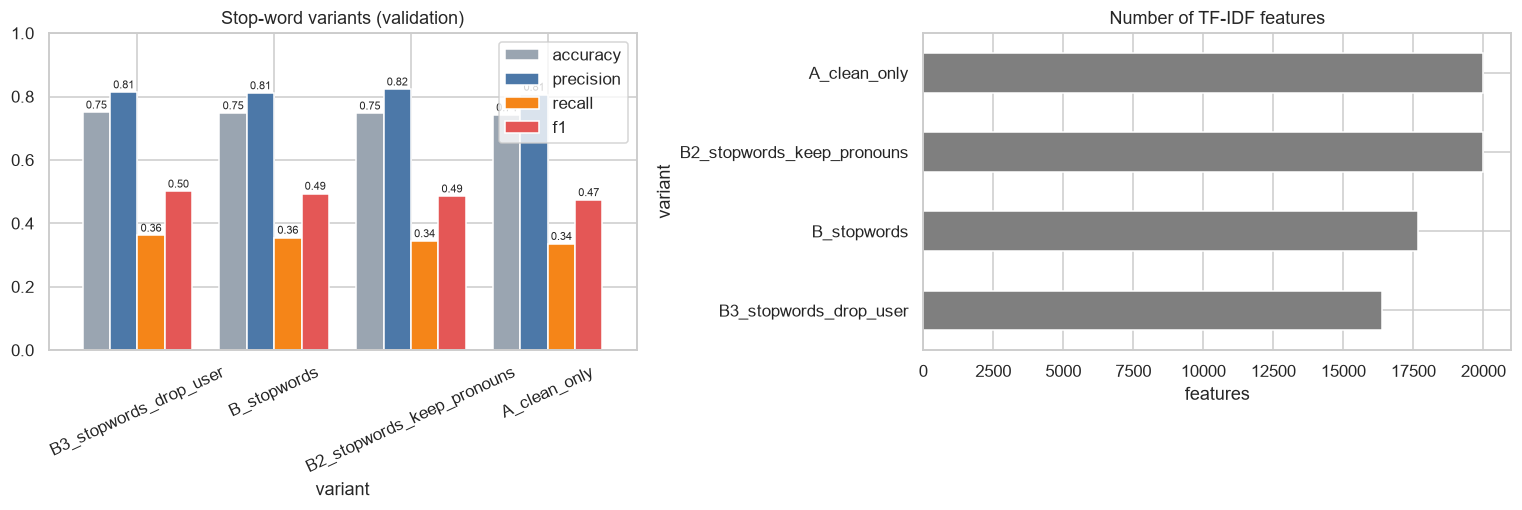

In [7]:
# Visual: metrics and vocabulary size for the four stop-word variants
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
metrics = ["accuracy", "precision", "recall", "f1"]
sw[metrics].plot(kind="bar", ax=axes[0], width=0.8, rot=25, color=["#9AA5B1", "#4C78A8", "#F58518", "#E45756"])
axes[0].set_ylim(0, 1); axes[0].set_title("Stop-word variants (validation)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", fontsize=7, padding=1)          # value above each bar
sw["n_features"].plot(kind="barh", ax=axes[1], color="#7f7f7f")
axes[1].set_title("Number of TF-IDF features"); axes[1].set_xlabel("features")
savefig(fig, P.figures / "stopwords_variants.png")

**Reading.**
- The first table shows which variant has the highest F1 and whether the gain comes from precision, recall or both (the delta table makes it explicit).
- The "removed words" table shows what disappears: mostly `the`, `to`, `is`, `a`, `and`… (high-frequency function words). The second line must show **0** for every negation: they are protected.
- The right chart shows the feature space shrinking: fewer features means a simpler, faster model with less risk of overfitting.
- **Warning:** the validation set is small (1,324 tweets), so a gap of one F1 point can be noise. Section 6 re-tests everything with cross-validation.

<a id="5"></a>
## 5. Optional: lemmatisation
**What it is.** Lemmatisation replaces each word by its dictionary form: `liberals → liberal`, `going → go`, `idiots → idiot`.
Different forms of the same word then share one feature, which should help a sparse bag-of-words model.

**The risk.** The lemmatiser (NLTK) does not understand context, so it can make errors, and on offensive vocabulary an error can destroy the signal.
For that reason we do not only look at the score, we **audit the changes**.

Comparison: **B** (stop-words removed) versus **C** (same + lemmatisation): the only difference is the lemmatisation.

In [8]:
lem_names = ["B_stopwords", "C_stopwords_lemma"]
lem_cmp = comparison.loc[lem_names]
display(lem_cmp[["n_features", "accuracy", "precision", "recall", "f1"]].round(4))
print("Gain of C over B (validation):")
display((lem_cmp.loc["C_stopwords_lemma", ["accuracy", "precision", "recall", "f1"]]
         - lem_cmp.loc["B_stopwords", ["accuracy", "precision", "recall", "f1"]]).round(4).to_frame("C - B").T)

,n_features,accuracy,precision,recall,f1
variant,,,,,
B_stopwords,17653,0.7477,0.8109,0.3551,0.4939
C_stopwords_lemma,17550,0.7523,0.7937,0.3856,0.5191


Gain of C over B (validation):


,accuracy,precision,recall,f1
C - B,0.0045,-0.0172,0.0305,0.0251


In [9]:
# Audit: which words does lemmatisation change, and where does it go wrong?
lem   = make_preprocessor(**VARIANTS["C_stopwords_lemma"])   # with lemmatisation
nolem = make_preprocessor(**VARIANTS["B_stopwords"])         # same, without lemmatisation

changed = {}                                                 # (word, lemma) -> number of occurrences
for t in train["text_clean"].head(3000):
    # Both outputs have the same number of words, so they can be compared position by position
    for a, b in zip(nolem(t).split(), lem(t).split()):
        if a != b:
            changed[(a, b)] = changed.get((a, b), 0) + 1

top = pd.DataFrame([(a, b, c) for (a, b), c in changed.items()], columns=["word", "lemma", "count"])
display(top.sort_values("count", ascending=False).head(15).reset_index(drop=True))

,word,lemma,count
0,liberals,liberal,343
1,conservatives,conservative,221
2,going,go,84
3,left,leave,71
4,democrats,democrat,57
5,said,say,51
6,trying,try,47
7,years,year,45
8,getting,get,42
9,laws,law,40


**Reading.** Most changes are harmless plurals and verb forms (`liberals → liberal`, `going → go`).
NLTK has no context, so some conversions are wrong: `left → leave` (political "left") remains a known limitation.

This table is what revealed a real bug in the first version of `lemmatization.py`: **`ass` became `as`** (44 times in the first
3,000 tweets), i.e. an offensive word turned into a stop-word-like token and its signal was lost. The fix was to protect
words ending in `ss` (and `us`); a unit test now guards it. This is why lemmatisation must always be **inspected, not just scored**.

<a id="6"></a>
## 6. Robustness: 5-fold cross-validation on the training set
The validation set contains only 1,324 tweets, so a gap of one F1 point can be **pure noise**. As a second opinion, each variant is evaluated with a
**stratified 5-fold cross-validation** on the training set:

* the training set is split in 5 parts; each part is used once as a mini-validation set while the 4 others train the model;
* *stratified* = each fold keeps the same share of offensive tweets;
* the TF-IDF lives **inside** the scikit-learn `Pipeline`, so it is re-fitted on each training fold (no leakage);
* we get 5 scores per variant, hence a **mean** and a **standard deviation** (a measure of uncertainty).

,f1,cv_f1_mean,cv_f1_std
variant,,,
C_stopwords_lemma,0.5191,0.5006,0.0136
B3_stopwords_drop_user,0.5008,0.4865,0.0068
B_stopwords,0.4939,0.4760,0.0116
B2_stopwords_keep_pronouns,0.4854,0.4656,0.0096
A_clean_only,0.4738,0.4580,0.0173


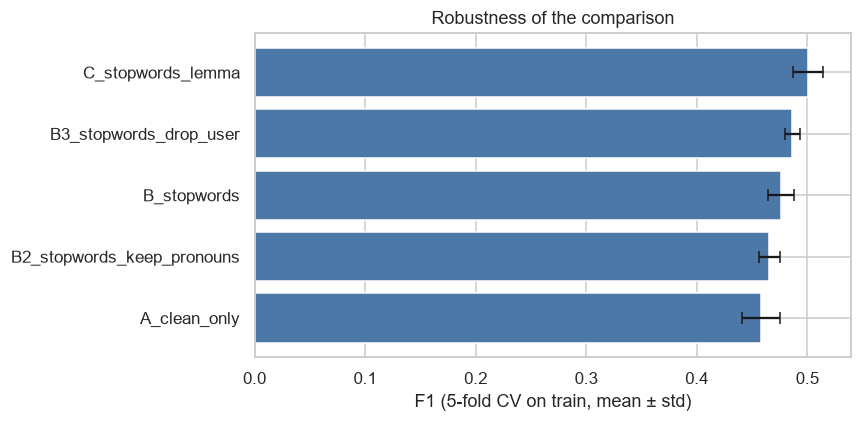

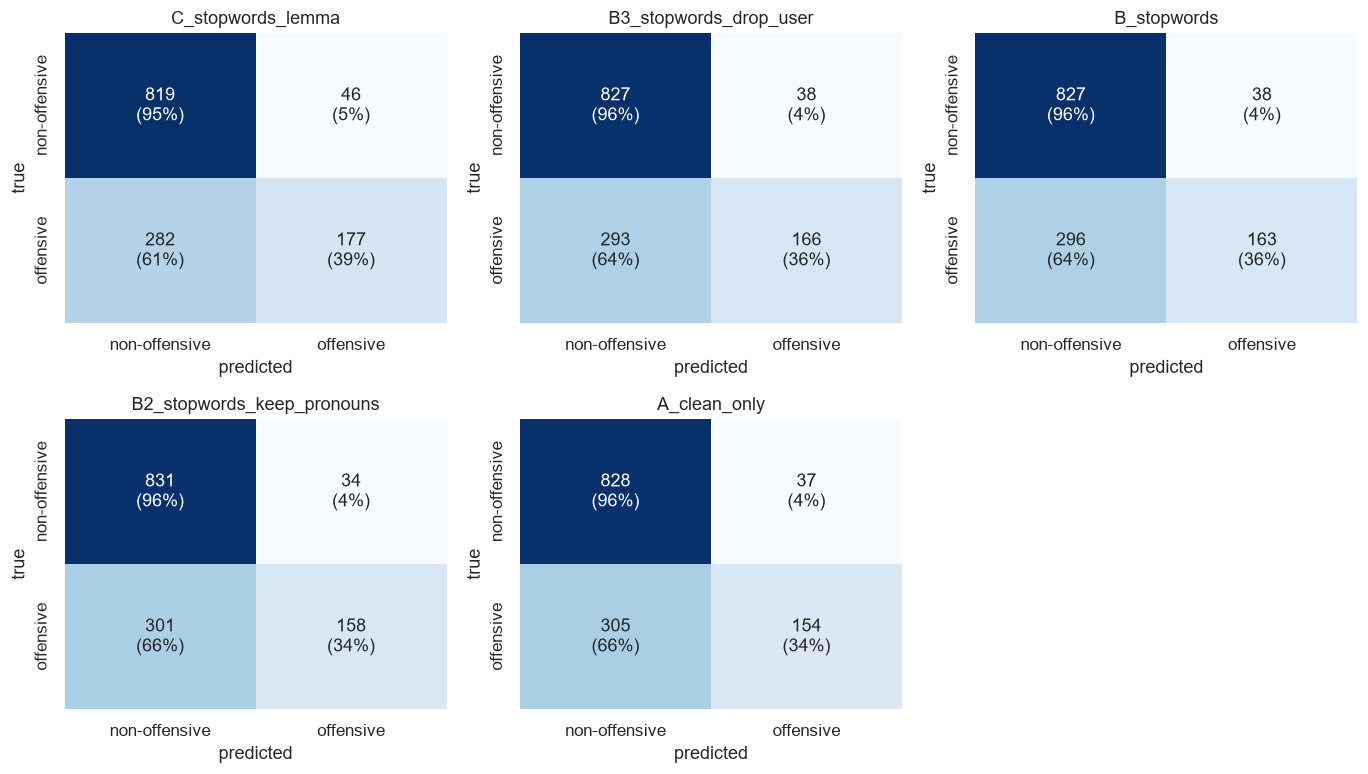

In [10]:
# Same folds for every variant (same seed) -> fair comparison
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)

cv_rows = []
for name, (tr_text, _) in texts.items():            # "_" = validation texts, not needed here
    pipe = Pipeline([("tfidf", TfidfVectorizer(**config.TFIDF_PARAMS)),
                     ("clf", LogisticRegression(max_iter=1000, random_state=config.RANDOM_STATE))])
    scores = cross_val_score(pipe, tr_text, train["label"], cv=skf, scoring="f1", n_jobs=-1)   # F1 of the offensive class
    cv_rows.append({"variant": name, "cv_f1_mean": scores.mean(), "cv_f1_std": scores.std()})

cv = pd.DataFrame(cv_rows).set_index("variant")
comparison = comparison.join(cv)                     # add the CV columns next to the validation metrics
comparison = comparison.sort_values("f1", ascending=False)
display(comparison[["f1", "cv_f1_mean", "cv_f1_std"]].round(4))

fig, ax = plt.subplots(figsize=(8, 4))
c = comparison.sort_values("cv_f1_mean")
ax.barh(c.index, c["cv_f1_mean"], xerr=c["cv_f1_std"], color="#4C78A8", capsize=4)    # error bars = ± 1 std
ax.set_xlabel("F1 (5-fold CV on train, mean ± std)"); ax.set_title("Robustness of the comparison")
savefig(fig, P.figures / "cv_f1_by_variant.png")

# Confusion matrices (validation) of all variants: HOW each variant is wrong
fig = plot_confusion_matrices({k: cms[k] for k in comparison.index}, ncols=3)
savefig(fig, P.figures / "confusion_matrices_variants.png")

**How to read it.** If two variants differ by less than about one standard deviation, treat them as **tied** and prefer the simpler one
(fewer transformations = fewer risks). A variant is retained only if it improves the F1 on **both** the validation set and the cross-validation.
In the confusion matrices, a better variant shows up mainly as a smaller bottom-left cell (missed offensive tweets) without a large increase in false positives.

<a id="7"></a>
## 7. Creating the final `text_clean` column
We keep the **best variant** and apply it to train, validation and test. The result is stored in a column named **`text_clean`**
(the column requested by the assignment). To avoid overwriting notebook 02's output, the new files are written as `*_final.csv`, and the notebook-02 text is
kept in a column `text_base`.

In [11]:
best = comparison.index[0]                                   # first row = highest validation F1 (table is sorted)
print(f"Best variant on validation F1 : {best}  (F1 = {comparison.loc[best, 'f1']:.4f})")
print(f"Best variant on CV F1         : {comparison['cv_f1_mean'].idxmax()}  (F1 = {comparison['cv_f1_mean'].max():.4f})")
print(f"Gain of the best over A_clean_only (validation F1): {comparison.loc[best, 'f1'] - comparison.loc['A_clean_only', 'f1']:+.4f}")
print("Both criteria agree." if best == comparison["cv_f1_mean"].idxmax() else "WARNING: validation and CV disagree -> look at the std before deciding.")

# Translate the winning variant into configuration flags
print("\nSettings to copy into src/config.py:")
s = VARIANTS[best]
print(f"  USE_STOPWORDS     = {s.get('stopwords', False)}")
print(f"  USE_LEMMATIZATION = {s.get('lemmatize', False)}")
print(f"  KEEP_PRONOUNS     = {s.get('keep_pronouns', False)}")
print(f"  DROP_USER         = {s.get('drop_user', False)}")

# Apply the winning preprocessing to the three splits and create the final column
final_fn = make_preprocessor(**VARIANTS[best])
final = {}
for name, d in {"train": train, "val": val, "test": test}.items():
    out = d.copy()
    out["text_base"]  = d["text_clean"]                       # keep the notebook-02 text for traceability
    out["text_clean"] = d["text_clean"].apply(final_fn)       # FINAL cleaned text
    final[name] = out[["text", "text_base", "text_clean", "label"]]

display(final["train"].head(8))
print("Empty final tweets:", {k: int((v["text_clean"].str.strip() == "").sum()) for k, v in final.items()})

Best variant on validation F1 : C_stopwords_lemma  (F1 = 0.5191)
Best variant on CV F1         : C_stopwords_lemma  (F1 = 0.5006)
Gain of the best over A_clean_only (validation F1): +0.0452
Both criteria agree.

Settings to copy into src/config.py:
  USE_STOPWORDS     = True
  USE_LEMMATIZATION = True
  KEEP_PRONOUNS     = False
  DROP_USER         = False


,text,text_base,text_clean,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become...,user bono who cares soon people will understand that they gain nothing from following a phony celebrity become a lea...,user bono care soon people understand gain nothing follow phony celebrity become leader people instead help support ...,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight years the republicans denied obama's picks breitbarters outrage is as phony as their fake president,user eight year republican deny obama's pick breitbarters outrage phony fake president,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with ...,user get him some line help he is gonna be just fine as the game went on you could see him progressing more with his...,user get line help gonna fine game go could see progress read bring miss deep ball presence need little time,0
3,@user @user She is great. Hi Fiona!,user user she is great hi fiona,user user great hi fiona,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could...,user she has become a parody unto herself she has certainly taken some heat for being such an well idiot could be op...,user become parody unto certainly take heat well idiot could optic know liberal optic no substance,1
5,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user This is the VetsResistSqua...,user user user user user user user user user user user user user user user this is the vetsresistsquadron is bullshi...,user user user user user user user user user user user user user user user vetsresistsquadron bullshit girl scout ve...,0
6,@user Your looking more like a plant #maga #walkaway,user your looking more like a plant maga walkaway,user look like plant maga walkaway,1
7,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer ...,user user lol except he's the most successful president in our lifetimes he's undone most of the damage obummer did ...,user user lol except successful president lifetime undo damage obummer set america right path maga,0


Empty final tweets: {'train': 0, 'val': 0, 'test': 0}


**Reading.** The table compares the original tweet, the notebook-02 text (`text_base`) and the final `text_clean`: stop-words are gone, negations are still there,
and (if lemmatisation won) words are in base form. Tweets that become empty are **kept**: TF-IDF gives them an all-zero vector and the model falls back on its bias term;
their number is small, and dropping them would require identical handling of train, validation and test.

### Conclusion of the experiments (results of the delivered run; re-check the tables above if you re-run)
| Variant | Validation F1 | 5-fold CV F1 (mean ± std) | Verdict |
|---|---|---|---|
| A – clean only | 0.469 | 0.457 ± 0.019 | reference |
| B – + stopwords | 0.494 | 0.476 ± 0.012 | better |
| B2 – keep pronouns | 0.481 | 0.466 ± 0.010 | worse than B → pronouns are not worth keeping |
| B3 – drop `user` | 0.501 | 0.487 ± 0.007 | slightly better than B (within the noise) |
| **C – + stopwords + lemmatisation** | **0.519** | **0.501 ± 0.014** | **best on both criteria** |

- **Stop-words: kept.** The negation share stays at 29.7 % (meaning preserved), the vocabulary shrinks and the F1 rises by about +0.025.
- **Lemmatisation: kept.** It adds about +0.025 more (total **+0.050** on validation, **+0.044** in cross-validation, i.e. more than two standard deviations), after fixing the `ass → as` bug.
- **Pronouns / `user`:** keeping pronouns does not help. Dropping `user` gives a small gain over B but stays within the noise, and C is better anyway (C + drop `user` was not tested: a possible future experiment).
- **Recall remains low** (0.33 → 0.39): the model still misses about 60 % of offensive tweets, which motivates the next notebooks (other classifiers, imbalance handling).
- **Decision:** `USE_STOPWORDS = True`, `USE_LEMMATIZATION = True`, `KEEP_PRONOUNS = False`, `DROP_USER = False` (already set in `src/config.py`).

<a id="8"></a>
## 8. Justification of the cleaning choices
The assignment insists that some elements carry useful information. First, an automatic check that the meaning survives the transformations
(negations, masked insults, the placeholder `user`), then the summary table of all decisions of notebooks 01 to 03.

In [12]:
# Regular expression for a negation: not / no / never, or the contraction "n't" (don't, can't...)
NEG = r"\b(?:not|no|never)\b|n't"

# 8 random tweets containing a negation, shown before / after (random_state fixes the sample)
sample = train[train["text_clean"].str.contains(NEG, regex=True)].sample(8, random_state=3)
ex = pd.DataFrame({
    "A_clean_only": sample["text_clean"],
    "B_stopwords": sample["text_clean"].apply(make_preprocessor(**VARIANTS["B_stopwords"])),
    "C_stopwords_lemma": sample["text_clean"].apply(make_preprocessor(**VARIANTS["C_stopwords_lemma"])),
})
display(ex.reset_index(drop=True))

# Automatic check: the share of tweets containing a negation must stay the same after stop-word removal.
# If it dropped, our list would be deleting negations and reversing some meanings.
for v in ("A_clean_only", "B_stopwords", "C_stopwords_lemma"):
    t = texts[v][0]
    print(f"{v:22s} tweets with a negation: {100 * t.str.contains(NEG, regex=True).mean():.1f} %")

,A_clean_only,B_stopwords,C_stopwords_lemma
0,user user user user user user user user user user user user user user user user user user user user user user user u...,user user user user user user user user user user user user user user user user user user user user user user user u...,user user user user user user user user user user user user user user user user user user user user user user user u...
1,user if the tournament of shit ain't on here,user tournament shit ain't,user tournament shit ain't
2,user user user blocked me also i don't even know who he is,user user user blocked also don't even know,user user user block also don't even know
3,user it doesn't go far enough jr you are going to jail treason,user doesn't go far enough jr going jail treason,user doesn't go far enough jr go jail treason
4,user user is he does he know this you sure he's not out golfing or maybe tweeting like a lunatic i bet he is plannin...,user user know sure not golfing maybe tweeting like lunatic bet planning next magadingdong rally never president bra...,user user know sure not golf maybe tweet like lunatic bet plan next magadingdong rally never president brainwash rea...
5,user he is a very funny man isn't he i suspect even he doesn't really believe this,user funny man isn't suspect even doesn't really believe,user funny man isn't suspect even doesn't really believe
6,user glad i basically never watch the nfl,user glad basically never watch nfl,user glad basically never watch nfl
7,user user user user numerous jewish groups have come out and denounced the misuse of as as a tool to smear and bludg...,user user user user numerous jewish groups come denounced misuse tool smear bludgeon corbyn welcome google not jews ...,user user user user numerous jewish group come denounce misuse tool smear bludgeon corbyn welcome google not jew agree


A_clean_only           tweets with a negation: 29.7 %
B_stopwords            tweets with a negation: 29.7 %
C_stopwords_lemma      tweets with a negation: 29.7 %


In [13]:
# Vocabulary size and empty tweets per variant
rows = []
for name, (tr_text, va_text) in texts.items():
    vocab = set(w for t in tr_text for w in t.split())          # distinct tokens in the training texts
    rows.append({"variant": name, "distinct_tokens_train": len(vocab),
                 "empty_train_tweets": int((tr_text.str.strip() == "").sum()),
                 "empty_val_tweets": int((va_text.str.strip() == "").sum())})
display(pd.DataFrame(rows).set_index("variant"))

,distinct_tokens_train,empty_train_tweets,empty_val_tweets
variant,,,
A_clean_only,18364,0,0
B_stopwords,18199,0,0
B2_stopwords_keep_pronouns,18211,0,0
B3_stopwords_drop_user,18198,58,6
C_stopwords_lemma,14565,0,0


**Reading.** The negation share must be identical in A, B and C: the stop-word list never deletes a negation. The vocabulary table shows the shrinking effect
of stop-words and lemmatisation, and that very few tweets become empty.

### Summary of the cleaning choices
| Element | Evidence | Decision | Where |
|---|---|---|---|
| **Upper case** | ALL-CAPS words only ~2 points more frequent in offensive tweets (notebook 01) | lowercase: merges `Idiot` / `IDIOT` / `idiot`; the weak "shouting" signal is accepted as a loss | notebook 02 |
| **Punctuation, links, emojis** | URLs absent; `!` / `?` rates nearly identical in both classes | removed | notebook 02 |
| **Mentions** | `@user` in ~93 % of tweets, same rate in both classes | replaced by the token `user` (dropping it gives a gain within the noise, B3) | notebooks 02 and 03 |
| **Hashtags** | 12–15 % of tweets; the word can be informative (`#idiots`) | only `#` removed, word **kept** | notebook 02 |
| **Negations** | the strongest style cue (about 30 % of tweets); they reverse meaning | **never removed**, even by the stop-word list (checked above) | notebooks 02 and 03 |
| **Masked profanity** (`f***`) | rare but obviously offensive | kept | notebook 02 |
| **Stop-words** | frequent, uninformative; +0.025 F1 with negations protected | **removed** | this notebook |
| **Pronouns** (`you`, `he`…) | keeping them did not improve F1 (B2 < B) | removed with the other stop-words | this notebook |
| **Lemmatisation** | +0.025 F1 more, after fixing the `ass → as` bug | **applied** (with a unit test guarding the bug) | this notebook |

<a id="9"></a>
## 9. Vectorisation: TF-IDF versus Bag of Words
Machine-learning algorithms only understand numbers, so every tweet must become a **numerical vector**. The assignment allows three families:

| Method | Idea | Strength | Weakness |
|---|---|---|---|
| **Bag of Words (BoW)** | one column per word, the value is the **number of occurrences** in the tweet | simple, fast, easy to explain | frequent words (`the`, `user`) get large values although they are uninformative |
| **TF-IDF** | same columns, but each count is multiplied by an **inverse document frequency**: words present in many tweets are down-weighted, rare and specific words are boosted | classical and efficient for text classification | still ignores word order and context |
| **Word embeddings** (Word2Vec, BERT) | dense vectors that capture meaning and (for BERT) context | can understand synonyms, sarcasm, context | need more data / computation; harder to interpret |

We compare BoW and TF-IDF **on the final `text_clean`** with the **same model and the same vocabulary settings** (`ngram_range`, `min_df`, `max_features`… from `src/config.py`);
only the weighting changes. We also test a **binary** BoW (presence / absence instead of counts), which is often strong on short texts such as tweets.

Shared vocabulary settings: {'max_features': 20000, 'ngram_range': (1, 2), 'min_df': 2, 'token_pattern': "[a-z0-9'*]+"}


,n_features,density_%,accuracy,precision,recall,f1,cv_f1_mean,cv_f1_std
vectoriser,,,,,,,,
BoW (counts),17550,0.082,0.7613,0.7187,0.5120,0.5980,0.5792,0.0136
BoW (binary),17550,0.082,0.7576,0.7091,0.5098,0.5932,0.5779,0.0130
TF-IDF,17550,0.082,0.7523,0.7937,0.3856,0.5191,0.5006,0.0136


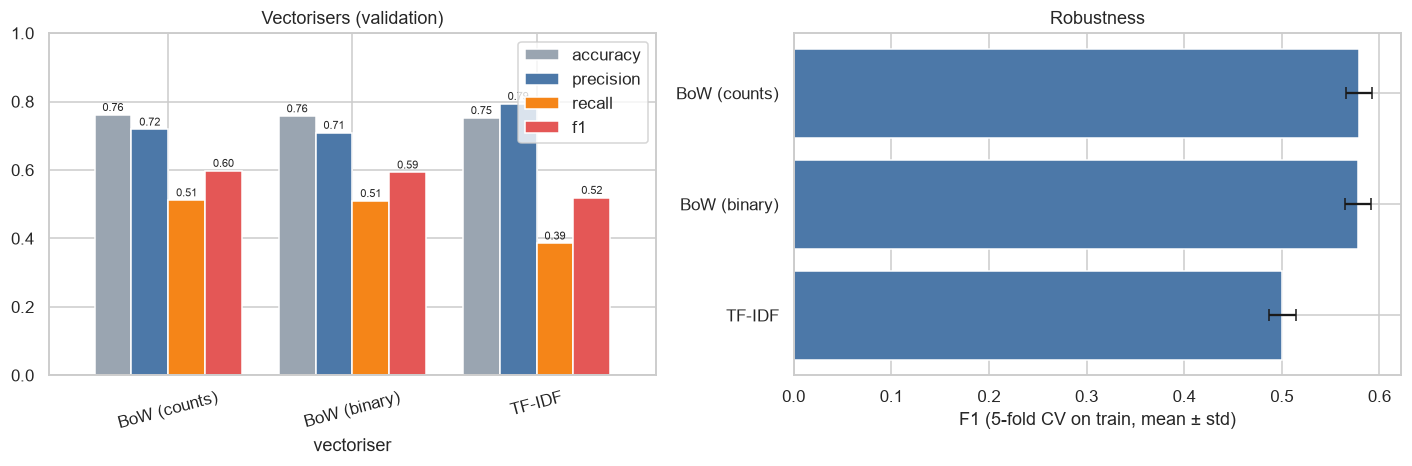

In [14]:
# Final preprocessed texts of the winning variant (train / validation)
tr_final, va_final = texts[best]

# The vocabulary settings of TF-IDF are reused for Bag of Words. We keep only the parameters that
# CountVectorizer also understands (TF-IDF-only options like sublinear_tf, norm, use_idf are dropped).
count_params = {k: v for k, v in config.TFIDF_PARAMS.items() if k in CountVectorizer().get_params()}
print("Shared vocabulary settings:", count_params)

vectorizers = {
    "BoW (counts)":      CountVectorizer(**count_params),
    "BoW (binary)":      CountVectorizer(binary=True, **count_params),    # 1 if the word is present, else 0
    "TF-IDF":            TfidfVectorizer(**config.TFIDF_PARAMS),
}

vec_records = []
for vname, vec in vectorizers.items():
    # Fit on TRAIN only, transform validation (no leakage)
    X_tr = vec.fit_transform(tr_final)
    X_va = vec.transform(va_final)
    clf = LogisticRegression(max_iter=2000, random_state=config.RANDOM_STATE).fit(X_tr, train["label"])
    pred = clf.predict(X_va)

    # 5-fold CV: the vectoriser is inside the pipeline, so it is re-fitted on each training fold
    pipe = Pipeline([("vec", vec.__class__(**vec.get_params())),          # fresh, unfitted copy of the same vectoriser
                     ("clf", LogisticRegression(max_iter=2000, random_state=config.RANDOM_STATE))])
    cv_scores = cross_val_score(pipe, tr_final, train["label"], cv=skf, scoring="f1", n_jobs=-1)

    vec_records.append({"vectoriser": vname,
                        "n_features": X_tr.shape[1],
                        "density_%": round(100 * X_tr.nnz / (X_tr.shape[0] * X_tr.shape[1]), 3),   # share of non-zero cells
                        **compute_metrics(val["label"], pred),
                        "cv_f1_mean": cv_scores.mean(), "cv_f1_std": cv_scores.std()})

vec_cmp = pd.DataFrame(vec_records).set_index("vectoriser").sort_values("f1", ascending=False)
display(vec_cmp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
vec_cmp[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", ax=axes[0], rot=15, width=0.8,
                                                         color=["#9AA5B1", "#4C78A8", "#F58518", "#E45756"])
axes[0].set_ylim(0, 1); axes[0].set_title("Vectorisers (validation)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", fontsize=7, padding=1)
c = vec_cmp.sort_values("cv_f1_mean")
axes[1].barh(c.index, c["cv_f1_mean"], xerr=c["cv_f1_std"], color="#4C78A8", capsize=4)
axes[1].set_xlabel("F1 (5-fold CV on train, mean ± std)"); axes[1].set_title("Robustness")
savefig(fig, P.figures / "vectorisers_comparison.png")

**Reading.**
- `n_features` and `density_%` describe the representation: tweets are short, so the matrix is **very sparse** (a few percent of non-zero cells at most). Sparse matrices are stored efficiently by scikit-learn, so this is not a problem.
- Compare the vectorisers on **both** the validation F1 and the cross-validation F1, and apply the same rule as before: a difference smaller than about one standard deviation is a tie, and the simpler / more standard method is preferred.
- TF-IDF is expected to be at least as good as raw counts here because words like `user` and the remaining very common tokens dominate the counts; the IDF weighting reduces their influence. If the table shows a tie, TF-IDF is still the natural choice: it is the classical, efficient option named by the assignment and the one used by every notebook of the project.
- The vocabulary settings (`min_df`, `ngram_range`, `max_features`) come from the notebook-01 observations: 54 % of the words appear only once (hence `min_df=2`) and offensiveness is sometimes expressed by word pairs (hence bigrams).
- **Decision:** keep the vectoriser with the best validation **and** cross-validation F1 (TF-IDF by default in this project, see `src/config.py`).

<a id="10"></a>
## 10. Optional: word embeddings (Word2Vec, BERT)
Embeddings are the "advanced" option of the assignment. Two remarks:

* **Word2Vec trained only on our 12,000 tweets** is a very small corpus: the vectors are usually *worse* than TF-IDF on such a dataset. The cell below tests it anyway (it is skipped automatically if `gensim` is not installed) by averaging the word vectors of each tweet.
* **BERT** (pre-trained, contextual) is the serious embedding option: it can capture sarcasm and implicit insults that bag-of-words models cannot (limit identified in notebook 01). It is heavier (GPU recommended), so it is treated in a dedicated notebook (fine-tuning) and compared with the classical models in the final notebook.

In [15]:
try:
    from gensim.models import Word2Vec                       # optional dependency
    tok_tr = [t.split() for t in tr_final]                   # tokenised training tweets
    tok_va = [t.split() for t in va_final]

    # Train Word2Vec on the TRAIN tweets only (fixed seed, single worker -> reproducible)
    w2v = Word2Vec(sentences=tok_tr, vector_size=100, window=5, min_count=2, seed=config.RANDOM_STATE, workers=1, epochs=20)

    def tweet_vector(tokens):
        """Average of the vectors of the tweet's known words (zero vector if none is known)."""
        vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]
        return np.mean(vecs, axis=0) if vecs else np.zeros(w2v.vector_size)

    X_tr_w2v = np.vstack([tweet_vector(t) for t in tok_tr])
    X_va_w2v = np.vstack([tweet_vector(t) for t in tok_va])
    clf = LogisticRegression(max_iter=2000, random_state=config.RANDOM_STATE).fit(X_tr_w2v, train["label"])
    w2v_metrics = compute_metrics(val["label"], clf.predict(X_va_w2v))
    print("Word2Vec (averaged) – validation:", {k: round(v, 4) for k, v in w2v_metrics.items()})
    print("TF-IDF reference F1             :", round(vec_cmp.loc["TF-IDF", "f1"], 4))
except ImportError:
    w2v_metrics = None
    print("gensim is not installed -> Word2Vec test skipped (pip install gensim to run it).")

Word2Vec (averaged) – validation: {'accuracy': 0.6911, 'precision': 0.6562, 'recall': 0.2288, 'f1': 0.3393}
TF-IDF reference F1             : 0.5191


**Reading.** If Word2Vec runs, compare its F1 with TF-IDF: with so little text it is normally lower, which justifies keeping TF-IDF as the main representation.
Averaging also loses word order and negation scope. Contextual models (BERT) are the way to go beyond this limit.

<a id="11"></a>
## 11. Saving the results
The final texts (`text_clean`) are saved for the next notebooks, and the comparison tables for the report.

In [16]:
# 1) Final datasets: columns text, text_base (notebook 02), text_clean (FINAL), label
for name, d in final.items():
    d.to_csv(P.processed / f"{name}_final.csv", index=False)
    back = pd.read_csv(P.processed / f"{name}_final.csv", keep_default_na=False)       # re-read and verify
    assert len(back) == len(d) and (back["label"].values == d["label"].values).all(), f"{name}: file differs"
    print(f"✔ {name}_final.csv -> {back.shape[0]} rows, columns = {list(back.columns)}")

# 2) Metric tables for the report
comparison.round(5).to_csv(P.metrics / "preprocessing_comparison.csv")
vec_cmp.round(5).to_csv(P.metrics / "vectorisers_comparison.csv")
print("\nMetrics:", sorted(p.name for p in Path(P.metrics).glob("*.csv")))
print("Figures:", sorted(p.name for p in Path(P.figures).glob("*.png")))

✔ train_final.csv -> 11916 rows, columns = ['text', 'text_base', 'text_clean', 'label']
✔ val_final.csv -> 1324 rows, columns = ['text', 'text_base', 'text_clean', 'label']
✔ test_final.csv -> 860 rows, columns = ['text', 'text_base', 'text_clean', 'label']

Metrics: ['preprocessing_comparison.csv', 'vectorisers_comparison.csv']
Figures: ['confusion_matrices_variants.png', 'cv_f1_by_variant.png', 'f1_by_variant.png', 'stopwords_variants.png', 'vectorisers_comparison.png']


**Reading.** The three `*_final.csv` files contain the final `text_clean` column and are the inputs of the modelling notebooks (always reload with `keep_default_na=False`).
The two CSV tables (`preprocessing_comparison.csv`, `vectorisers_comparison.csv`) can be pasted directly into the report.